# Vessel Turnaround Time Prediction (Brazilian Port Operations)

## Summary

**Question:** can information known when a vessel arrives predict its total port stay (`t_total_port_stay_h`)?

**Answer: partly.** It works well for typical stays, but not for very long ones.

| Test period (Jul - Dec 2025, 21,002 calls) | MAE (h) | RMSE (h) | Median absolute error (h) |
|---|---|---|---|
| Baseline: median stay per port | 45.7 | 92.6 | 20.1 |
| **Final LightGBM model** | **38.0** | **80.0** | **15.0** |

**Key findings**

- **Better than the baseline overall:** the model's MAE is 16.9% lower. The test MAE (38.0 h) is close to
  the validation MAE (41.6 h), so the choices made on validation hold on unseen data.
- **Long stays drive the error:** stays over 7 days are 9% of calls but cause 49% of the total error, and
  99% of them are predicted too short. For stays under 3 days (71% of calls) the MAE is 14 - 17 h.
- **Past behaviour matters most:** the model relies mainly on how long similar earlier calls took. Route
  history accounts for 51% of feature importance, then the port (17%) and vessel history (10%).
- **Larger improvement at Santos:** at Santos (BRSSZ), where congestion and stays are highest, the model
  improves on the baseline by 24% (other ports 15%), but long stays there are still poorly predicted.
- **The extra features did not help:** the external source (Brazilian public holidays, `holidays` library),
  the weather features and my own EDA features changed the validation MAE by 0.07 h or less. That is the same
  as the run-to-run variation between random seeds, so they were left out.
- **Data cleanup did not help either:** removing records with matching port, arrival and stay, and stays
  under 1 hour, made no measurable difference, so all records were kept.
- **Main limitation:** the dataset has no vessel type, size or cargo volume. These are likely drivers of the
  long stays.

**Approach in brief:** I used a time-based split (train 2023 - Jun 2024, validation Jul 2024 - Jun 2025, test
Jul - Dec 2025). Only features available at arrival were used, checked against the data dictionary. The
baseline is the median stay per port. The model is LightGBM trained with MAE loss. I made every choice on
validation, retrained on train + validation, and evaluated on the test period only once.

**Sections:** 2 Dataset · 3 EDA and external data · 4 Feature preparation · 5 Modelling and experiments ·
6 Final evaluation on the test set

---

## 1. Introduction

### 1.1 Context

Vessel turnaround time is an important indicator of port operational efficiency. Predicting the duration of a vessel's stay can support port planning, resource allocation, and operational decision making.

This analysis investigates whether historical vessel port call records and information available at the time of arrival can be used to predict total port-stay duration.


### 1.2 Objective

The objective is to develop and evaluate a regression model for predicting vessel turnaround time.

The analysis will:

- Explore the dataset and assess its quality.
- Investigate the distribution of the target variable.
- Identify potentially useful predictive features.
- Establish a baseline model.
- Develop a regression model and compare it with the baseline.
- Evaluate predictive performance on an unseen test set.




## 2. Dataset Description

The analysis uses the Brazilian Port Calls & Lead Time 2023–2025 dataset, available on [Kaggle](https://www.kaggle.com/datasets/tiagoalberione/brazilian-port-lead-time-2023-2025).

The dataset contains historical port-call records from Brazilian ports. It includes arrival-related information, weather features, operational indicators, port-level statistics, and vessel-related historical features.

The dataset's data dictionary, from its [GitHub repository](https://github.com/tiagoalberione/port-leadtime-prediction), was used to understand the feature definitions.

### 2.1 Prediction Objective

The target variable is `t_total_port_stay_h`, representing the total duration of a vessel's port stay in hours.

The prediction is intended to be made at the time of vessel arrival. Therefore, predictors must be available at that point in time. Information recorded after arrival must not be used as a predictor, as it would introduce data leakage.

### 2.2 Dataset Loading and Initial Inspection


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#read the dataset
df = pd.read_csv(
    "brazilian_port_calls_model_ready_2023_2025.csv"
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (129625, 124)


,port_call_id,arrival_port_ts,t_total_port_stay_h,split,port,region,state,arrival_shift,arrival_season,arrival_quarter,arrival_weekofyear,arrival_is_weekend,arrival_hour_sin,arrival_hour_cos,arrival_dow_sin,arrival_dow_cos,arrival_month_sin,arrival_month_cos,rain_sum_prev_1d,precipitation_sum_prev_1d,wind_speed_10m_max_prev_1d,wind_gusts_10m_max_prev_1d,temperature_2m_mean_prev_1d,rain_sum_prev_3d,precipitation_hours_prev_3d,temperature_2m_mean_prev_3d,wind_speed_10m_max_prev_3d,wind_gusts_10m_max_prev_3d,rain_sum_prev_7d,precipitation_hours_prev_7d,temperature_2m_mean_prev_7d,wind_speed_10m_max_prev_7d,wind_gusts_10m_max_prev_7d,op_abastecimento_bunker,op_arribada,op_carga,op_descarga,op_desembarque_passageiros,op_embarque_passageiros,op_fundeio,op_fundeio_ship_to_ship,op_navio_estado_com_operacao_comercial,op_navio_estado_marinha_brasil,op_navio_estado_sem_operacao_comercial,op_offshore,op_reparo_manutencao,op_retirada_residuos_com_operacao_comercial,op_retirada_residuos_sem_operacao_comercial,op_solicitacao_certificado,op_tipo_operacao_nao_mapeado,arrivals_prev_1d,arrivals_prev_3d,arrivals_prev_7d,arrivals_avg_prev_3d,arrivals_max_prev_3d,arrivals_avg_prev_7d,arrivals_max_prev_7d,departures_prev_1d,departures_prev_3d,departures_prev_7d,departures_avg_prev_3d,departures_max_prev_3d,departures_avg_prev_7d,departures_max_prev_7d,flow_balance_prev_1d,flow_balance_prev_3d,flow_balance_prev_7d,port_wait_known_count,port_wait_known_mean,port_wait_known_median,port_wait_known_std,port_wait_known_q90,port_wait_known_q95,port_operation_known_count,port_operation_known_mean,port_operation_known_median,port_operation_known_std,port_operation_known_q90,port_operation_known_q95,port_total_known_count,port_total_known_mean,port_total_known_median,port_total_known_std,port_total_known_q90,port_total_known_q95,state_waiting_vessels_d_minus_1,state_berthed_vessels_d_minus_1,state_present_vessels_d_minus_1,state_backlog_vessels_d_minus_1,state_entry_exit_delta_prev_1d,vessel_total_known_count,vessel_total_known_mean,vessel_total_known_median,vessel_total_known_q90,vessel_wait_known_count,vessel_wait_known_mean,vessel_wait_known_median,vessel_wait_known_q90,vessel_port_total_known_count,vessel_port_total_known_mean,vessel_port_total_known_median,vessel_port_total_known_q90,source_total_known_count,source_total_known_mean,source_total_known_median,source_total_known_q90,destination_total_known_count,destination_total_known_mean,destination_total_known_median,destination_total_known_q90,route_total_known_count,route_total_known_mean,route_total_known_median,route_total_known_q90,opmix_carga_share_prev_3d,opmix_descarga_share_prev_3d,opmix_fundeio_share_prev_3d,opmix_offshore_share_prev_3d,opmix_reparo_manutencao_share_prev_3d,opmix_carga_share_prev_7d,opmix_descarga_share_prev_7d,opmix_fundeio_share_prev_7d,opmix_offshore_share_prev_7d,opmix_reparo_manutencao_share_prev_7d
0,22023,2023-01-04T16:17:00,29.283333,train,BR052001,NORTE,PA,afternoon,summer,1,1,0,-0.866025,-5.000000e-01,0.974928,-0.222521,0.0,1.0,22.2,22.2,5.4,22.3,26.0,41.2,45.0,25.900000,10.9,24.5,82.2,114.0,25.914286,10.9,29.9,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,2.0,19.108333,19.108333,31.995000,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,5492023,2023-01-06T05:18:00,29.900000,train,BR052001,NORTE,PA,night,summer,1,1,0,0.965926,2.588190e-01,-0.433884,-0.900969,0.0,1.0,18.7,18.7,9.7,26.3,27.1,62.8,48.0,26.566667,9.7,26.3,103.2,114.0,26.242857,10.9,29.9,False,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,0.0,1.0,1.0,0.333333,1.0,0.142857,1.0,1.0,1.0,1.0,0.333333,1.0,0.142857,1.0,-1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,29.

### 2.3 Data Dictionary and Leakage

The Kaggle dataset provides only the model-ready CSV. To interpret its columns, the data dictionary
from the dataset's [GitHub repository](https://github.com/tiagoalberione/port-leadtime-prediction)
was used. The dictionary covers the full data pipeline, so it also describes raw and
intermediate columns that are not part of the model-ready file. It also records, for each column,
whether it is available at prediction time, which is used for the leakage check below.

In [2]:
dictionary = pd.read_csv(
    "data_dictionary.csv"
)

# Keep only the dictionary entries for columns present in the dataset
dictionary_in_data = dictionary[dictionary["column"].isin(df.columns)]

print("Dictionary entries:", len(dictionary))
print("Entries for columns in this dataset:", len(dictionary_in_data))

#display the dictionary entries for columns present in the dataset
display(dictionary_in_data)


Dictionary entries: 207
Entries for columns in this dataset: 124


,column,dtype,description,source,transformation,availability_at_prediction_time,modeling_role,included_in_analytical,included_in_model_ready,notes
0,port_call_id,int64,Unique source DUV identifier of the consolidat...,Porto Sem Papel vessel-stay records,Cleaned and standardized identifier retained f...,not_applicable,identifier,True,True,Taken from the public DUV field and used as th...
1,port,string,Brazilian port code where the vessel call occu...,Porto Sem Papel vessel-stay records,Standardized from the Porto - Bitrigrama field...,yes,feature,True,True,Included in the model-ready dataset as an offi...
11,arrival_port_ts,datetime64[ns],Timestamp when the vessel arrived at the port;...,Porto Sem Papel vessel-stay records,Parsed arrival timestamp from vessel-stay reco...,yes,metadata,True,True,Prediction timestamp. Features in the model-re...
41,t_total_port_stay_h,float64,"Total vessel port stay in hours, from arrival_...",Derived by project pipeline,Computed as departure_port_ts minus arrival_po...,not_applicable,target,True,True,Main supervised-learning target.
58,arrival_quarter,int32,Calendar quarter of arrival.,Derived by project pipeline,Derived from arrival_port_ts.,yes,feature,True,True,Included in the model-ready dataset as an offi...
...,...,...,...,...,...,...,...,...,...,...
202,opmix_carga_share_prev_7d,float64,Recent historical operation mix share at the s...,Derived by project pipeline,Reconstructed historical feature using a D-1 c...,historical_only,feature,False,True,Included in the model-ready dataset as an offi...
203,opmix_descarga_share_prev_7d,float64,Recent historical operation mix share at the s...,Derived by project pipeline,Reconstructed historical feature using a D-1 c...,historical_only,feature,False,True,Included in the model-ready dataset as an offi...
204,opmix_fundeio_share_prev_7d,float64,Recent historical operation mix share at the s...,Derived by project pipeline,Reconstructed historical feature using a D-1 c...,historical_only,feature,False,True,Included in the model-ready dataset as an offi...
205,opmix_offshore_share_prev_7d,float64,Recent historical operation mix share at the s...,Derived by project pipeline,Reconstructed historical feature using a D-1 c...,historical_only,feature,False,True,Included in the model-ready dataset as an offi...


In [3]:
display(
    dictionary[
        dictionary["modeling_role"].astype(str).str.contains(
            "target", case=False, na=False
        )
    ][["column", "description", "modeling_role"]]
)

,column,description,modeling_role
41,t_total_port_stay_h,"Total vessel port stay in hours, from arrival_...",target


In [4]:
dictionary_columns = set(dictionary["column"])
dataset_columns = set(df.columns)

print("Columns in dictionary but not in dataset:", len(dictionary_columns - dataset_columns))

print("Columns in dataset but not in dictionary:", len(dataset_columns - dictionary_columns))

not_in_data = dictionary[~dictionary["column"].isin(df.columns)]
display(not_in_data["modeling_role"].value_counts().to_frame("Columns not in dataset"))

Columns in dictionary but not in dataset: 83
Columns in dataset but not in dictionary: 0


,Columns not in dataset
modeling_role,
leakage_do_not_use,55
metadata,12
identifier,10
eda_only,6


**Leakage** means using information that is not available at the moment of prediction. For example,
the departure time would give the stay exactly: the model would score very well in testing but be
useless in practice. The prediction is made at arrival, so the dictionary's
`availability_at_prediction_time` field is checked for every column in the dataset.

In [5]:
display(
    dictionary_in_data
    .groupby(["availability_at_prediction_time", "modeling_role"])
    .size()
    .to_frame("Columns")
)

Columns
availability_at_prediction_time modeling_role         
historical_only                 feature             89
not_applicable                  identifier           1
                                metadata             1
                                target               1
yes                             feature             31
                                metadata             1

**My observations:**

- 83 dictionary columns are not in the file: 55 marked `leakage_do_not_use` (post-arrival timestamps and the
  waiting/operation durations that add up to the target), 12 metadata, 6 EDA-only and 10 identifiers
  (e.g. `vessel_id`, `imo`).
- Every column in the file is documented in the dictionary.
- Of the 120 feature columns, 31 are `yes` (known directly at arrival) and 89 are `historical_only`
  (calculated from calls whose outcome was known by the end of the previous day). None is marked as
  unavailable at prediction time.
- The history features cannot be recomputed from this file (no vessel IDs or post-arrival timestamps), so this
  relies on the data dictionary.
- Not usable as features: `port_call_id`, `arrival_port_ts`, `split` and the target.


## 3. Exploratory Data Analysis (EDA)

### 3.1 Column Overview

The data dictionary describes every column, and the column names follow a pattern: the first part of the
name says what the column describes (e.g. `vessel_`, `port_`, `rain_`). The prefixes are counted first.

In [6]:
prefixes = pd.Series([col.split("_")[0] for col in df.columns])
display(prefixes.value_counts().to_frame("Number of columns"))

,Number of columns
port,20
op,17
arrival,12
vessel,12
opmix,10
arrivals,7
departures,7
state,6
wind,6
source,4


Using these prefixes and the dictionary descriptions, related prefixes are combined into groups. For example,
`rain_`, `precipitation_`, `wind_` and `temperature_` are all weather before arrival, while `op_` (operations
declared for this call) and `opmix_` (recent operation mix at the port) are kept apart. Columns that do not
follow the pattern (identifiers, location, target) are assigned by name.

In [7]:
def column_group(col):
    """Assign each column to a feature group based on its name."""
    if col in ("port_call_id", "arrival_port_ts", "split"):
        return "Identifier / metadata"
    if col == target:
        return "Target"
    if col in ("port", "region", "state"):
        return "Location"
    if col.startswith("arrival_"):
        return "Arrival calendar"
    if col.startswith(("rain_", "precipitation_", "wind_", "temperature_")):
        return "Weather (before arrival)"
    if col.startswith("opmix_"):
        return "Port operation mix (before arrival)"
    if col.startswith("op_"):
        return "Declared operation type"
    if col.startswith(("arrivals_", "departures_", "flow_balance_", "state_")):
        return "Port traffic & congestion (before arrival)"
    if col.startswith("port_"):
        return "Port history"
    if col.startswith("vessel_"):
        return "Vessel history"
    if col.startswith(("source_", "destination_", "route_")):
        return "Route history"
    return "Other"


target = "t_total_port_stay_h"
groups = pd.Series({col: column_group(col) for col in df.columns}, name="group")

group_summary = (
    groups.reset_index()
    .groupby("group")["index"]
    .agg(n_columns="count", example_columns=lambda c: ", ".join(c[:3]))
    .sort_values("n_columns", ascending=False)
)
display(group_summary)
print("Column data types:")
display(df.dtypes.value_counts().to_frame("Number of columns"))

,n_columns,example_columns
group,,
Port traffic & congestion (before arrival),22,"arrivals_prev_1d, arrivals_prev_3d, arrivals_p..."
Port history,18,"port_wait_known_count, port_wait_known_mean, p..."
Declared operation type,17,"op_abastecimento_bunker, op_arribada, op_carga"
Weather (before arrival),15,"rain_sum_prev_1d, precipitation_sum_prev_1d, w..."
Route history,12,"source_total_known_count, source_total_known_m..."
Vessel history,12,"vessel_total_known_count, vessel_total_known_m..."
Arrival calendar,11,"arrival_shift, arrival_season, arrival_quarter"
Port operation mix (before arrival),10,"opmix_carga_share_prev_3d, opmix_descarga_shar..."
Identifier / metadata,3,"port_call_id, arrival_port_ts, split"


Column data types:


,Number of columns
float64,96
bool,17
object,7
int64,4


**My observations:**

- Information available at arrival: location, calendar, declared operations, weather, port traffic and
  congestion, and port, vessel and route history.
- Vessel characteristics (type, size, cargo volume) are not included, and there is no vessel identifier to
  join them from another source.

### 3.2 Dataset Splits

The dataset comes with a predefined `split` column. The arrival dates in each split are checked
to understand how the data was partitioned.

In [8]:

print("Dataset partitions:")
display(
    df.groupby("split")
    .agg(
        Record_Count=("port_call_id", "count"),
        Unique_Port_Calls=("port_call_id", "nunique")
    )
)


Dataset partitions:


,Record_Count,Unique_Port_Calls
split,,
calibration,21352,21352
final_test,21002,21002
train,66909,66909
validation,20362,20362


,first_arrival,last_arrival
split,,
train,2023-01-01 00:08:00,2024-06-30 23:30:00
validation,2024-07-01 00:00:00,2024-12-31 22:40:00
calibration,2025-01-01 00:05:00,2025-06-30 23:40:00
final_test,2025-07-01 00:00:00,2025-12-31 23:00:00


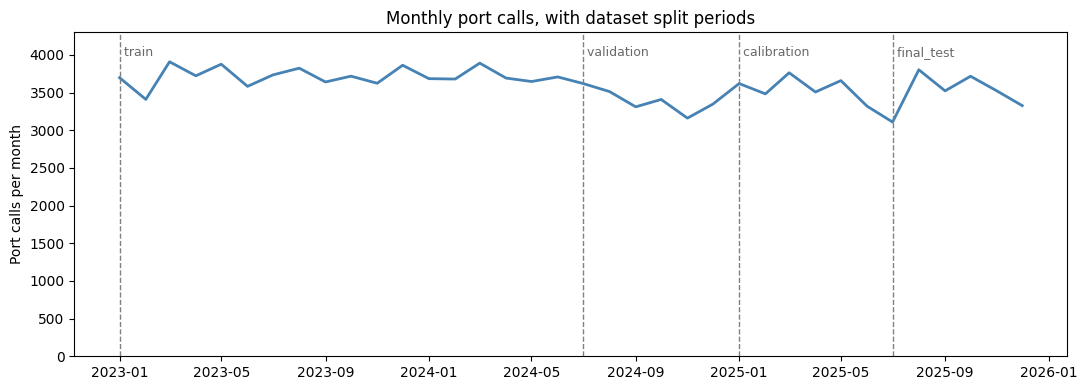

In [9]:
df["arrival_ts"] = pd.to_datetime(df["arrival_port_ts"])

split_order = ["train", "validation", "calibration", "final_test"]
display(
    df.groupby("split")["arrival_ts"]
    .agg(first_arrival="min", last_arrival="max")
    .loc[split_order]
)

# Number of port calls per month, with the split periods marked
monthly_calls = df.set_index("arrival_ts").resample("MS").size()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly_calls.index, monthly_calls.values, color="steelblue", linewidth=2)
for split_name in split_order:
    start = df.loc[df["split"] == split_name, "arrival_ts"].min()
    ax.axvline(start, color="grey", linestyle="--", linewidth=1)
    ax.text(start, monthly_calls.max() * 1.02, f" {split_name}", color="dimgrey", fontsize=9)
ax.set_ylabel("Port calls per month")
ax.set_title("Monthly port calls, with dataset split periods")
ax.set_ylim(0, monthly_calls.max() * 1.1)
plt.tight_layout()
plt.show()

**My observations:**

- The split is time-based: train Jan 2023 - Jun 2024, validation Jul - Dec 2024, calibration Jan - Jun 2025,
  final test Jul - Dec 2025.
- Monthly call volume is stable at roughly 3,100 - 3,900 calls.

**Split used for modelling:** the calibration split is meant for tuning prediction intervals, i.e. a range
such as "between 20 and 60 hours" instead of a single number. This analysis predicts a single number per call,
so calibration is merged into validation, giving a 12-month validation period (Jul 2024 - Jun 2025).
`final_test` is kept unchanged as the holdout.

In [10]:
# Merge the calibration split into validation
df["model_split"] = df["split"].replace({"calibration": "validation"})

display(
    df.groupby("model_split")["arrival_ts"]
    .agg(port_calls="count", first_arrival="min", last_arrival="max")
    .loc[["train", "validation", "final_test"]]
)

,port_calls,first_arrival,last_arrival
model_split,,,
train,66909,2023-01-01 00:08:00,2024-06-30 23:30:00
validation,41714,2024-07-01 00:00:00,2025-06-30 23:40:00
final_test,21002,2025-07-01 00:00:00,2025-12-31 23:00:00


**Development data:** data-quality checks and the overall description of the target (Sections 3.3 - 3.5)
use the full dataset. From Section 3.6 onwards, which looks at how features relate to the stay, only the
development data is used (train + validation, Jan 2023 - Jun 2025), so `final_test` does not influence
feature or model choices. It is used once, for the final evaluation.

In [11]:
# Columns used in the analysis below
df["arrival_month"] = df["arrival_ts"].dt.month
df["arrival_weekday"] = df["arrival_ts"].dt.day_name().str[:3]
df["has_vessel_history"] = df["vessel_total_known_count"] > 0

# Feature analysis uses development data only; final_test is held out
dev = df[df["model_split"] != "final_test"].copy()
print(f"Development data: {len(dev):,} calls,",
      dev["arrival_ts"].min().date(), "to", dev["arrival_ts"].max().date())

Development data: 108,623 calls, 2023-01-01 to 2025-06-30


### 3.3 Missing Values and Constant Columns

Missing values are counted per column and then summarised per column group, to see whether they
are scattered randomly or concentrated in particular groups.

In [12]:

# Summarise dataset structure and completeness
column_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Non-Null Count": df.notna().sum(),
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

print("\nTotal missing values:", df.isna().sum().sum())

print("\nColumns with missing values:")
display(
    column_summary[column_summary["Missing Count"] > 0]
    .sort_values("Missing Percentage", ascending=False)
)



Total missing values: 869502

Columns with missing values:


,Data Type,Non-Null Count,Missing Count,Missing Percentage,Unique Values
vessel_port_total_known_q90,float64,39859,89766,69.25,26690
vessel_port_total_known_median,float64,39859,89766,69.25,7771
vessel_port_total_known_mean,float64,39859,89766,69.25,35936
vessel_total_known_mean,float64,41917,87708,67.66,38121
vessel_total_known_median,float64,41917,87708,67.66,6154
vessel_total_known_q90,float64,41917,87708,67.66,25431
vessel_wait_known_q90,float64,41973,87652,67.62,9072
vessel_wait_known_median,float64,41973,87652,67.62,265
vessel_wait_known_mean,float64,41973,87652,67.62,20424
route_total_known_median,float64,109880,19745,15.23,13652


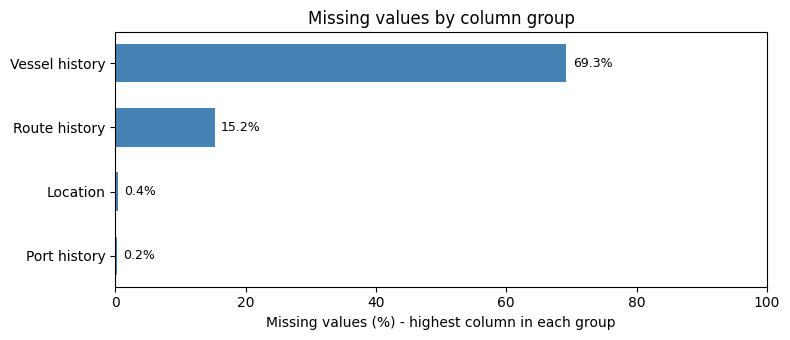

In [13]:
missing_by_group = (
    df.isna().mean().mul(100)
    .groupby(groups)
    .max()
    .loc[lambda s: s > 0]
    .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing_by_group.index, missing_by_group.values, color="steelblue", height=0.6)
for i, value in enumerate(missing_by_group.values):
    ax.text(value + 1, i, f"{value:.1f}%", va="center", fontsize=9)
ax.set_xlabel("Missing values (%) - highest column in each group")
ax.set_title("Missing values by column group")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

The history columns (`*_known_*`) describe earlier visits, e.g. `vessel_total_known_mean` is the
average stay of the same vessel on its earlier known visits. According to the data dictionary,
these use a D-1 cutoff and only events known before arrival.

If the missing values occur because there is no earlier history, they should line up exactly with
the matching `*_known_count` column being 0. This is checked below.

**How to read the tables:** rows split the calls by whether the count is 0 (no earlier visit), and columns by
whether the history value is missing. If missing values mean "no history", every call falls in one of two
cells: count 0 and missing, or count above 0 and not missing. The other two cells should be 0.

In [14]:
history_checks = {
    "Vessel history": ("vessel_total_known_count", "vessel_total_known_mean"),
    "Vessel at this port": ("vessel_port_total_known_count", "vessel_port_total_known_mean"),
    "Route history": ("route_total_known_count", "route_total_known_mean"),
    "Source port history": ("source_total_known_count", "source_total_known_mean"),
    "Port history": ("port_total_known_count", "port_total_known_mean"),
}

for name, (count_col, mean_col) in history_checks.items():
    print(name)
    display(pd.crosstab(
        df[count_col] == 0,
        df[mean_col].isna(),
        rownames=[f"{count_col} == 0"],
        colnames=[f"{mean_col} is missing"],
    ))

Vessel history


vessel_total_known_mean is missing,False,True
vessel_total_known_count == 0,,
False,41917,0
True,0,87708


Vessel at this port


vessel_port_total_known_mean is missing,False,True
vessel_port_total_known_count == 0,,
False,39859,0
True,0,89766


Route history


route_total_known_mean is missing,False,True
route_total_known_count == 0,,
False,109880,0
True,0,19745


Source port history


source_total_known_mean is missing,False,True
source_total_known_count == 0,,
False,128073,0
True,0,1552


Port history


port_total_known_mean is missing,False,True
port_total_known_count == 0,,
False,129333,0
True,0,292


A column where every row has the same value carries no information, and it would not show up in the
missing-values table above. The columns with the fewest distinct values are listed:

In [15]:
unique_counts = df.nunique(dropna=False).sort_values()
display(unique_counts.head(5).to_frame("Unique values"))

constant_columns = unique_counts[unique_counts == 1].index.tolist()

,Unique values
op_tipo_operacao_nao_mapeado,1
has_vessel_history,2
op_solicitacao_certificado,2
op_retirada_residuos_sem_operacao_comercial,2
op_retirada_residuos_com_operacao_comercial,2


**My observations:**

- Missing values are concentrated in the history features: vessel history (about 68 - 69%), route history (15%),
  source/destination history (about 1%) and port history (0.1 - 0.2%).
- `state` and `region` are missing for 0.4% of calls (port code not matched in the port reference).
- History values are missing exactly when the matching `*_known_count` is 0, i.e. when there is no earlier
  known visit. They are not random gaps.
- `op_tipo_operacao_nao_mapeado` is constant (always False).

### 3.4 Target Variable

The target, `t_total_port_stay_h`, is the total port stay in hours. It is checked for missing, zero or
negative values, and its distribution is examined on the original and log scale and across the splits.

In [16]:

# Check target data quality
print("Target variable:", target)
print("Missing values:", df[target].isna().sum())
print("Negative durations:", (df[target] < 0).sum())
print("Zero durations:", (df[target] == 0).sum())

# Descriptive statistics
print("\nTarget descriptive statistics:")

display(
    df[target].describe(
        percentiles=[
            0.01, 0.05, 0.25, 0.50,
            0.75, 0.90, 0.95, 0.99
        ]
    ).to_frame()
)


Target variable: t_total_port_stay_h
Missing values: 0
Negative durations: 0
Zero durations: 0

Target descriptive statistics:


,t_total_port_stay_h
count,129625.000000
mean,71.103869
std,97.116162
min,0.016667
1%,1.750000
5%,6.333333
25%,18.900000
50%,38.416667
75%,80.833333
90%,163.083333


The shortest stay is about 1 minute, so very short stays are looked at more closely:

In [17]:
op_columns = [col for col in df.columns if col.startswith("op_")]

short_stay_thresholds = [0.5, 1, 2]
for threshold in short_stay_thresholds:
    count = (df[target] < threshold).sum()
    print(f"Stays shorter than {threshold} hours: {count:,} ({count / len(df) * 100:.2f}%)")

display(
    df.loc[df[target] < 1, op_columns].sum()
    .sort_values(ascending=False).head(5)
    .to_frame("Port calls with stay < 1 hour")
)

Stays shorter than 0.5 hours: 299 (0.23%)
Stays shorter than 1 hours: 598 (0.46%)
Stays shorter than 2 hours: 1,429 (1.10%)


,Port calls with stay < 1 hour
op_offshore,385
op_carga,121
op_descarga,77
op_solicitacao_certificado,15
op_desembarque_passageiros,11


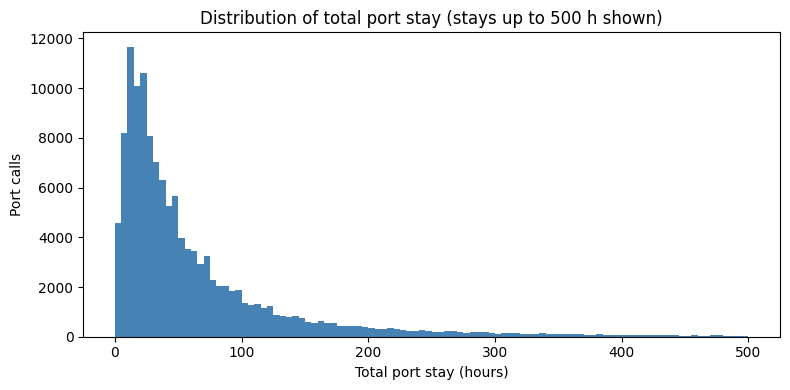

Skewness: 3.51


In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df[target], bins=100, range=(0, 500), color="steelblue")
ax.set_xlabel("Total port stay (hours)")
ax.set_ylabel("Port calls")
ax.set_title("Distribution of total port stay (stays up to 500 h shown)")
plt.tight_layout()
plt.show()

print("Skewness:", round(df[target].skew(), 2))

**My observations:**

- The target has no missing, zero or negative values. The shortest stay is about 1 minute; 598 stays (0.46%)
  are under 1 hour, mostly offshore calls (385).
- It is strongly right-skewed (skewness 3.5): most stays are short, but a long tail of very long stays pulls the
  mean (71 h) far above the median (38 h). The 90th percentile is 163 h, the 99th 528 h and the maximum 1,280 h.

Because a small number of very long stays stretch the distribution, the target is also examined on a
log scale, using `log(1 + stay)` (`np.log1p`).

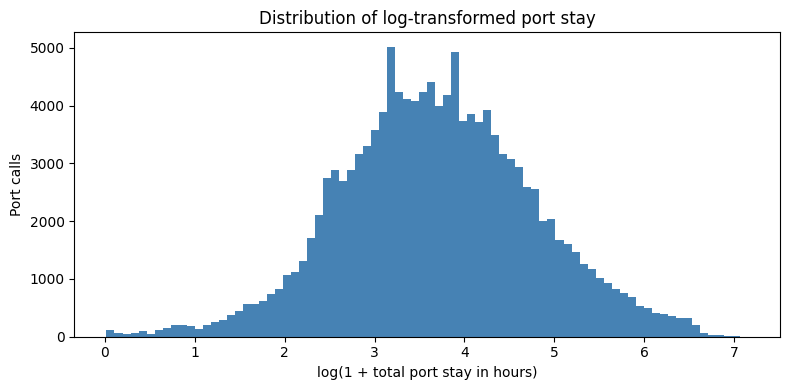

Skewness after log transform: 0.0


In [19]:
log_target = np.log1p(df[target])

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(log_target, bins=80, color="steelblue")
ax.set_xlabel("log(1 + total port stay in hours)")
ax.set_ylabel("Port calls")
ax.set_title("Distribution of log-transformed port stay")
plt.tight_layout()
plt.show()

print("Skewness after log transform:", round(log_target.skew(), 2))

**My observations:**

- On the log scale the distribution is roughly symmetric (skewness about 0), so the very long stays no longer
  dominate.

Target statistics by modelling split (calibration merged into validation):


,count,mean,median,std,min,max
model_split,,,,,,
train,66909,70.02,36.90,97.58,0.02,1272.58
validation,41714,73.20,40.14,99.13,0.02,1280.08
final_test,21002,70.40,39.72,91.36,0.02,967.75


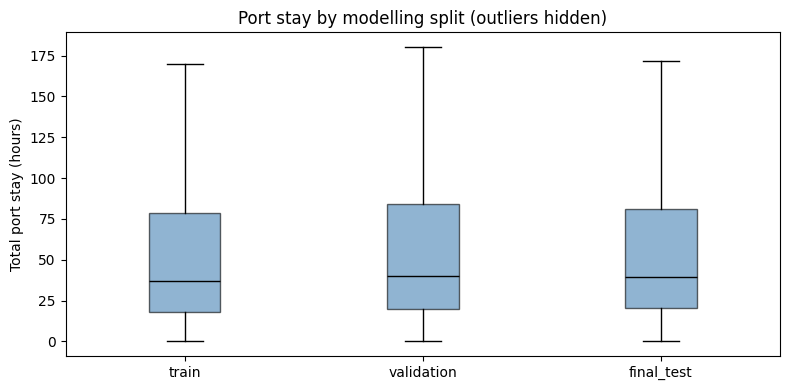

In [20]:
model_split_order = ["train", "validation", "final_test"]

print("Target statistics by modelling split (calibration merged into validation):")
display(
    df.groupby("model_split")[target]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .loc[model_split_order]
    .round(2)
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.boxplot(
    [df.loc[df["model_split"] == s, target] for s in model_split_order],
    showfliers=False, patch_artist=True,
    boxprops=dict(facecolor="steelblue", alpha=0.6), medianprops=dict(color="black"),
)
ax.set_xticks(range(1, len(model_split_order) + 1), model_split_order)
ax.set_ylabel("Total port stay (hours)")
ax.set_title("Port stay by modelling split (outliers hidden)")
plt.tight_layout()
plt.show()

**My observations:**

- The three modelling splits have similar distributions. Validation (Jul 2024 - Jun 2025) stays are slightly
  longer: median 40.1 h vs 36.9 h in train and 39.7 h in the final test.

### 3.5 Extreme Port Stays and Records Sharing a Visit

The longest stays are inspected to see whether they look like errors or unusual operations. Extreme values
are not removed only because of their size.

Besides the stay, the table shows the operations declared for the call (the `op_*` columns that are True),
the number of vessels waiting at the port on the previous day, and `vessel_total_known_count`, the number of
earlier visits by the same vessel known at arrival (0 = no earlier visit on record).

In [21]:
# The 20 longest stays, with their declared operations and context at arrival
longest_port_calls = df.nlargest(20, target).copy()
longest_port_calls["declared_operations"] = longest_port_calls[op_columns].apply(
    lambda row: ", ".join(col.replace("op_", "") for col in op_columns if row[col]), axis=1
)
display(longest_port_calls[[
    "port_call_id", "arrival_port_ts", "port", "split", target,
    "declared_operations", "state_waiting_vessels_d_minus_1", "vessel_total_known_count",
]].round(1))

,port_call_id,arrival_port_ts,port,split,t_total_port_stay_h,declared_operations,state_waiting_vessels_d_minus_1,vessel_total_known_count
93308,478362024,2024-10-23T06:00:00,BRSFS,validation,1280.1,descarga,4.0,0.0
101182,207152023,2023-05-26T13:55:00,BRSSZ,train,1272.6,carga,40.0,0.0
36291,226462024,2024-07-03T16:04:00,BRPEC,validation,1144.4,"carga, descarga",1.0,0.0
36183,191192024,2024-05-12T10:48:00,BRPEC,train,1140.7,descarga,3.0,0.0
36184,267582024,2024-05-12T10:48:00,BRPEC,train,1140.7,carga,3.0,0.0
103365,472032023,2023-10-27T18:00:00,BRSSZ,train,1137.8,carga,12.0,0.0
120719,425692023,2023-09-27T03:00:00,BRTRM001,train,1119.5,descarga,1.0,0.0
108047,401772024,2024-09-14T14:54:00,BRSSZ,validation,1111.2,descarga,46.0,0.0
108048,460032024,2024-09-14T14:54:00,BRSSZ,validation,1111.2,carga,46.0,0.0
117568,259352024,2024-06-07T14:01:00,BRSUA,train,1107.5,descarga,6.0,0.0


**My observations:**

- The longest stays (up to about 1,280 h, or 53 days) are loading, unloading and offshore calls, not repairs.
  Several are at Santos (BRSSZ) with 30 - 46 vessels waiting on the previous day.
- 18 of the 20 have no earlier visit on record.
- 6 of the 20 come in pairs (consecutive rows in the table) with the same port, arrival minute and stay, but
  different `port_call_id` and different operations, e.g. 191192024 (unloading) and 267582024 (loading) at
  BRPEC, both arriving 2024-05-12 10:48 and staying 1,140.7 h.

To see how common these pairs are, every record that has the same port, arrival time (to the minute) and
stay as at least one other record is marked. Records identical in every column except `port_call_id` are
counted separately.

In [22]:
# Mark every record whose port, arrival time and stay match at least one other record
same_visit_key = ["port", "arrival_port_ts", target]
shares_visit = df.duplicated(subset=same_visit_key, keep=False)

# Mark records identical to another record in every column except the ID
identical = df.duplicated(subset=[col for col in df.columns if col != "port_call_id"], keep=False)

print(f"Records sharing a visit: {shares_visit.sum():,} ({shares_visit.mean() * 100:.2f}%)")
print(f"Number of shared visits: {df[shares_visit].groupby(same_visit_key).ngroups}")
print(f"Records identical except the ID: {identical.sum()}")

# Check that records of the same visit never end up in different splits
splits_per_visit = df[shares_visit].groupby(same_visit_key)["model_split"].nunique()
print(f"Shared visits spread over more than one split: {(splits_per_visit > 1).sum()}")
print(f"Median stay - records sharing a visit: {df.loc[shares_visit, target].median():.1f} h, "
      f"all records: {df[target].median():.1f} h")

Records sharing a visit: 1,394 (1.08%)
Number of shared visits: 673
Records identical except the ID: 164
Shared visits spread over more than one split: 0
Median stay - records sharing a visit: 225.3 h, all records: 38.4 h


The operations declared by the records within each shared visit, e.g. `carga | descarga` means one
record declares loading and the other unloading:

In [23]:
shared = df[shares_visit].copy()
shared["operations"] = shared[op_columns].apply(
    lambda row: "+".join(col.replace("op_", "") for col in op_columns if row[col]), axis=1
)
operations_per_visit = shared.groupby(same_visit_key)["operations"].apply(lambda ops: " | ".join(sorted(ops)))
display(operations_per_visit.value_counts().head(5).to_frame("Shared visits"))

,Shared visits
operations,
carga | descarga,349
offshore | offshore,86
descarga | descarga,33
carga+descarga | carga+descarga,33
carga | carga,33


**My observations:**

- 1,394 records (1.1%) share port, arrival time and stay with at least one other record, in 673 groups
  (mostly pairs).
- The most common pattern is one loading and one unloading record (349 groups). Only 164 records are identical
  in every column except the ID.
- No shared visit is spread over more than one split, since its records have the same arrival time.
- Their median stay is 225 h, against 38 h overall, so they are concentrated among the long stays.
- They may be one visit recorded once per operation, true duplicates, or vessels arriving together. Without a
  vessel identifier this cannot be confirmed.

### 3.6 Port Stay by Port

There are many ports of very different sizes. The median stay is compared for the 15 busiest ports.

Medians are used instead of means because the target is right-skewed: a small number of very long
stays (e.g. over 500 hours) pull the mean upwards, so the mean does not represent a typical port call.
The median is much less sensitive to these extreme values than the mean.

Number of ports: 108
Share of calls at the 15 busiest ports: 68.4%
Median stay across ports with at least 100 calls: 1.6 - 207.5 h


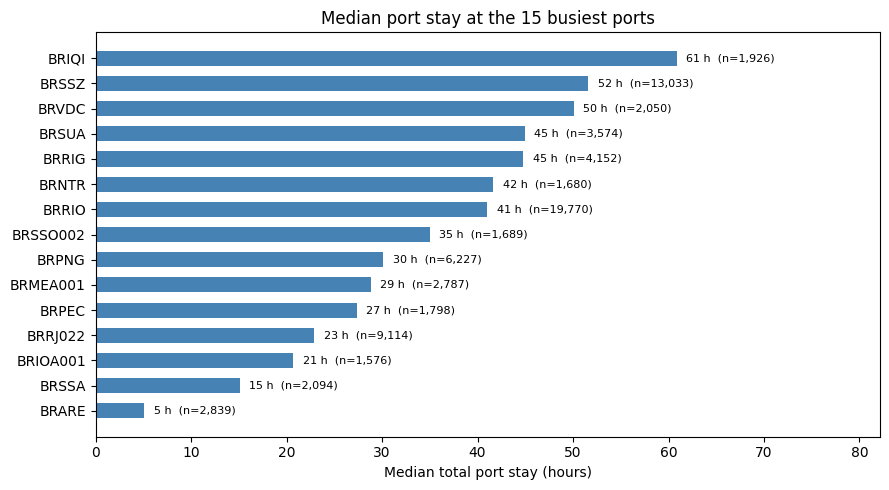

Validation calls at ports not seen in training: 98 (7 ports)


In [24]:
print("Number of ports:", dev["port"].nunique())

port_stats = (
    dev.groupby("port")[target]
    .agg(port_calls="count", median_stay="median")
    .sort_values("port_calls", ascending=False)
)
print("Share of calls at the 15 busiest ports:",
      f"{port_stats['port_calls'].head(15).sum() / len(dev) * 100:.1f}%")

ports_100 = port_stats[port_stats["port_calls"] >= 100]
print(f"Median stay across ports with at least 100 calls: "
      f"{ports_100['median_stay'].min():.1f} - {ports_100['median_stay'].max():.1f} h")

top_ports = port_stats.head(15).sort_values("median_stay")

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_ports.index, top_ports["median_stay"], color="steelblue", height=0.6)
for i, (calls, stay) in enumerate(zip(top_ports["port_calls"], top_ports["median_stay"])):
    ax.text(stay + 1, i, f"{stay:.0f} h  (n={calls:,})", va="center", fontsize=8)
ax.set_xlabel("Median total port stay (hours)")
ax.set_title("Median port stay at the 15 busiest ports")
ax.set_xlim(0, top_ports["median_stay"].max() * 1.35)
plt.tight_layout()
plt.show()

# Ports in the validation data that never appear in the training data
train_ports = set(dev.loc[dev["model_split"] == "train", "port"])
validation = dev[dev["model_split"] == "validation"]
unseen = ~validation["port"].isin(train_ports)
print(f"Validation calls at ports not seen in training: {unseen.sum()} "
      f"({validation.loc[unseen, 'port'].nunique()} ports)")

**My observations:**

- There are 108 ports, and the 15 busiest account for 68% of calls.
- Median stay differs strongly by port: from about 5 h (BRARE) to 61 h (BRIQI) among the 15 busiest, and from
  about 2 h to 208 h across ports with at least 100 calls.
- 98 validation calls (7 ports) are at ports that never appear in training.

### 3.7 Port Stay by Declared Operation Type

The `op_*` columns are flags parsed from the declared operation type (e.g. `carga` = loading,
`descarga` = unloading, `fundeio` = anchorage, `abastecimento_bunker` = bunkering). A call can have
several operations at once, so the number of declared operations per call is counted first.

In [25]:
df["n_operations"] = df[op_columns].sum(axis=1)
dev["n_operations"] = df.loc[dev.index, "n_operations"]

print("Number of declared operations per port call (all data):")
display(df["n_operations"].value_counts().sort_index().to_frame("Port calls"))

Number of declared operations per port call (all data):


,Port calls
n_operations,
0,20
1,94822
2,34041
3,322
4,118
5,13
6,9
8,2
9,88


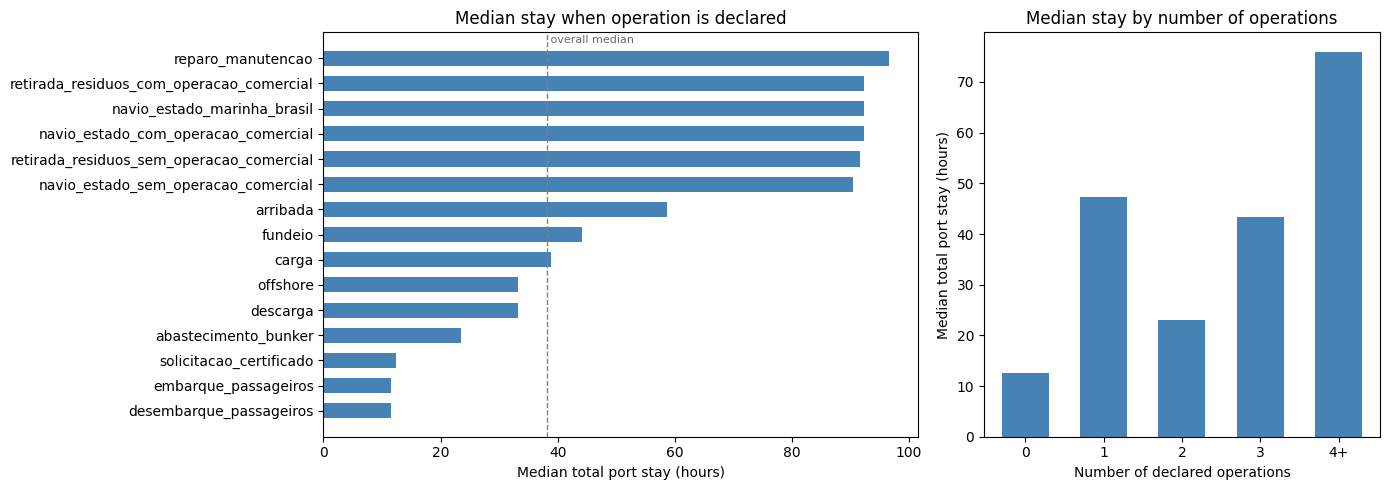

,port_calls,median_stay
loading only,26021,60.2
unloading only,21354,56.0
loading + unloading,25506,23.6


In [26]:
op_stats = pd.DataFrame({
    "port_calls": dev[op_columns].sum(),
    "median_stay": [dev.loc[dev[col], target].median() for col in op_columns],
}).query("port_calls >= 100").sort_values("median_stay")
op_stats.index = op_stats.index.str.replace("op_", "")

fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [3, 2]})

axes[0].barh(op_stats.index, op_stats["median_stay"], color="steelblue", height=0.6)
axes[0].axvline(dev[target].median(), color="grey", linestyle="--", linewidth=1)
axes[0].text(dev[target].median(), len(op_stats) - 0.4, " overall median", color="dimgrey", fontsize=8)
axes[0].set_xlabel("Median total port stay (hours)")
axes[0].set_title("Median stay when operation is declared")

ops_grouped = dev["n_operations"].clip(upper=4)
ops_median = dev.groupby(ops_grouped)[target].median()
axes[1].bar(ops_median.index.astype(str), ops_median.values, color="steelblue", width=0.6)
axes[1].set_xticks(range(len(ops_median)), ["0", "1", "2", "3", "4+"])
axes[1].set_xlabel("Number of declared operations")
axes[1].set_ylabel("Median total port stay (hours)")
axes[1].set_title("Median stay by number of operations")

plt.tight_layout()
plt.show()

# Loading and unloading on their own vs together
loading_unloading = {
    "loading only": dev["op_carga"] & (dev["n_operations"] == 1),
    "unloading only": dev["op_descarga"] & (dev["n_operations"] == 1),
    "loading + unloading": dev["op_carga"] & dev["op_descarga"] & (dev["n_operations"] == 2),
}
display(pd.DataFrame({
    "port_calls": {name: mask.sum() for name, mask in loading_unloading.items()},
    "median_stay": {name: dev.loc[mask, target].median() for name, mask in loading_unloading.items()},
}).round(1))

**My observations:**

- Most calls declare 1 or 2 operations. 20 declare none, and 278 declare 9 - 16 at once, which looks like a
  recording issue.
- Longest median stays: repair/maintenance (about 97 h), state/navy vessels and waste removal (about 90 - 92 h),
  emergency calls (`arribada`, about 59 h).
- Around the overall median (38 h): anchorage, loading, unloading and offshore (about 33 - 44 h).
- Shortest: bunkering (about 24 h), certificate requests (about 13 h) and passenger calls (about 12 h).
- The stay does not rise with the number of operations: 2-operation calls have a shorter median (23 h) than
  1-operation calls (47 h). Most 2-operation calls are loading + unloading (median 24 h), while loading-only or
  unloading-only calls have a median of 56 - 60 h.

### 3.8 Port Stay over Time

Monthly median stay over the full period, and the median by month of year, weekday and arrival shift.

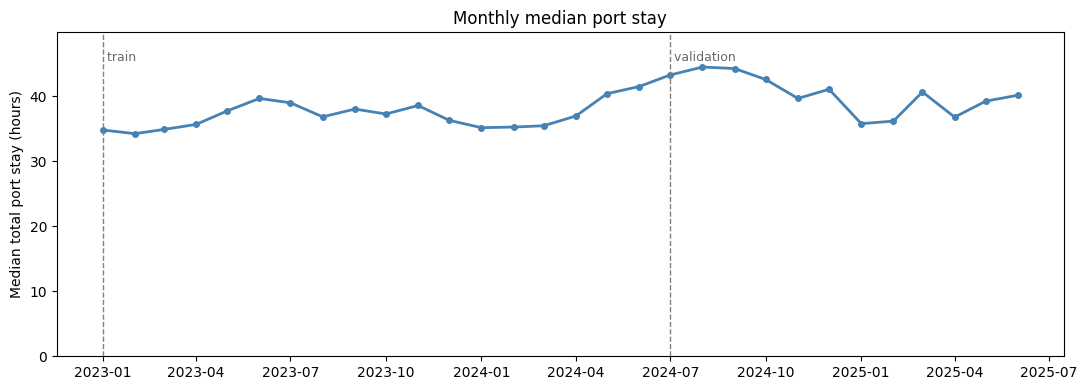

In [27]:
monthly_median = dev.set_index("arrival_ts")[target].resample("MS").median()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(monthly_median.index, monthly_median.values, color="steelblue", linewidth=2, marker="o", markersize=4)
for split_name in ["train", "validation"]:
    start = dev.loc[dev["model_split"] == split_name, "arrival_ts"].min()
    ax.axvline(start, color="grey", linestyle="--", linewidth=1)
    ax.text(start, monthly_median.max() * 1.02, f" {split_name}", color="dimgrey", fontsize=9)
ax.set_ylabel("Median total port stay (hours)")
ax.set_title("Monthly median port stay")
ax.set_ylim(0, monthly_median.max() * 1.12)
plt.tight_layout()
plt.show()

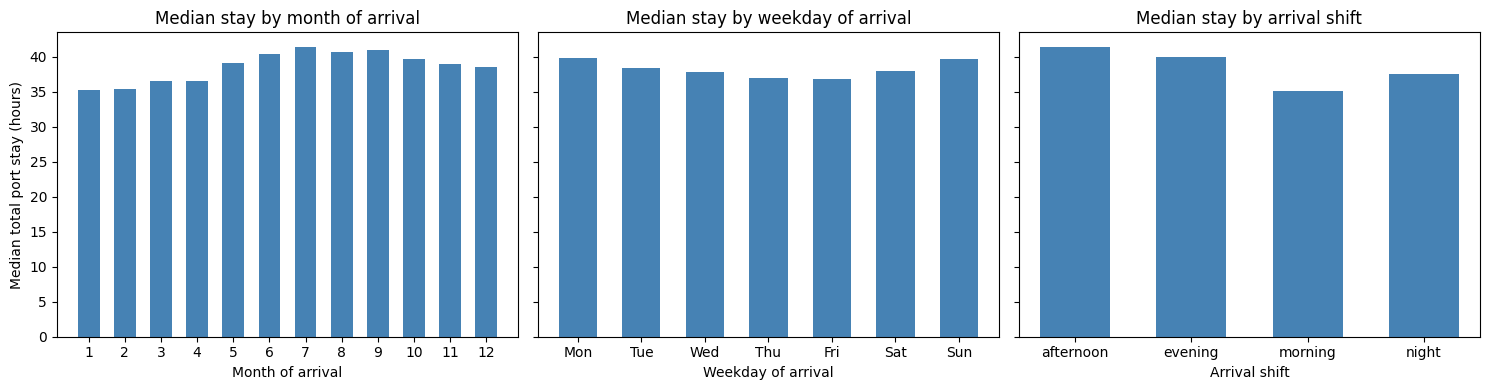

In [28]:
weekday_order = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
calendar_views = [
    ("arrival_month", "Month of arrival", list(range(1, 13))),
    ("arrival_weekday", "Weekday of arrival", weekday_order),
    ("arrival_shift", "Arrival shift", None),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (col, label, order) in zip(axes, calendar_views):
    medians = dev.groupby(col)[target].median()
    if order is not None:
        medians = medians.reindex(order)
    ax.bar(medians.index.astype(str), medians.values, color="steelblue", width=0.6)
    ax.set_xlabel(label)
    ax.set_title(f"Median stay by {label.lower()}")
axes[0].set_ylabel("Median total port stay (hours)")
plt.tight_layout()
plt.show()

**My observations:**

- The monthly median stay stays between about 34 and 45 h, peaking at about 45 h in August 2024 (validation period).
- Stays are slightly shorter in January - April (about 35 - 37 h) than in June - September (about 40 - 41 h).
- Weekday and shift differences are small: about 37 - 40 h by weekday; 35 h for morning vs 41 h for afternoon arrivals.

### 3.9 External Data: Brazilian Public Holidays

Port activity is often reduced around public holidays, especially Carnival and Christmas, which could lengthen
the stay of vessels arriving just before them. Brazilian national and state holidays are retrieved from the
[`holidays`](https://pypi.org/project/holidays/) Python library, including optional holidays such as Carnival.
Each port's own state is used, and national holidays only where the state is unknown.

For each call, the number of holidays on the arrival day and the 6 days after it is counted. Holiday dates are
known in advance, so this is available at arrival.

In [29]:
import holidays  # pip install holidays

years = range(df["arrival_ts"].dt.year.min(), df["arrival_ts"].dt.year.max() + 2)


def holiday_dates(state=None):
    """National holidays, plus the state's own holidays when a state is given."""
    calendar = holidays.Brazil(years=years, subdiv=state, categories=("public", "optional"))
    return {pd.Timestamp(day) for day in calendar}


national_holidays = holiday_dates()
state_holidays = {state: holiday_dates(state) for state in df["state"].dropna().unique()}

# Number of holidays on the arrival day and the 6 days after it
arrival_day = df["arrival_ts"].dt.normalize()
df["holidays_next_7d"] = 0
for offset in range(7):
    day = arrival_day + pd.Timedelta(days=offset)
    df["holidays_next_7d"] += [
        d in state_holidays.get(s, national_holidays) for s, d in zip(df["state"], day)
    ]
dev["holidays_next_7d"] = df.loc[dev.index, "holidays_next_7d"]

display(df["holidays_next_7d"].value_counts().sort_index().to_frame("Port calls"))

,Port calls
holidays_next_7d,
0,96996
1,23435
2,7239
3,1934
4,21


Because the stay depends strongly on the port, it is also compared with the port's usual stay
(stay divided by the port's median stay, so 1.0 = typical for that port).

In [30]:
dev["stay_vs_port_median"] = dev[target] / dev.groupby("port")[target].transform("median")

print("By number of holidays in the 7 days from arrival:")
display(
    dev.groupby(dev["holidays_next_7d"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"}))
    .agg(port_calls=(target, "size"), median_stay=(target, "median"),
         median_vs_port=("stay_vs_port_median", "median"))
    .round(2)
)

# Arrivals in the 7 days up to Carnival or Christmas, compared with all arrivals
national_calendar = holidays.Brazil(years=years, categories=("public", "optional"))
windows = {}
for name, label in [("Carnaval", "Carnival"), ("Natal", "Christmas")]:
    in_window = pd.Series(False, index=dev.index)
    for holiday in [pd.Timestamp(d) for d, n in national_calendar.items() if n == name]:
        in_window |= dev["arrival_ts"].dt.normalize().between(holiday - pd.Timedelta(days=6), holiday)
    windows[f"7 days up to {label}"] = dev[in_window]
windows["all arrivals"] = dev

display(pd.DataFrame({
    name: {"port_calls": len(calls), "median_stay": calls[target].median(),
           "median_vs_port": calls["stay_vs_port_median"].median()}
    for name, calls in windows.items()
}).T.astype({"port_calls": int}).round(2))

By number of holidays in the 7 days from arrival:


,port_calls,median_stay,median_vs_port
holidays_next_7d,,,
0,82233,38.08,1.00
1,18893,38.42,1.01
2+,7497,37.80,1.00


,port_calls,median_stay,median_vs_port
7 days up to Carnival,3019,36.75,1.02
7 days up to Christmas,1623,39.85,1.02
all arrivals,108623,38.17,1.00


**My observations:**

- About a quarter of calls have at least one holiday in the 7 days from arrival.
- The median stay is about 38 h whether 0, 1 or 2+ holidays are coming up, and the stay relative to the port's
  usual stay is 1.00 - 1.01.
- Arrivals in the week up to Carnival or Christmas stay about 2% longer than usual for their port (1.02), a
  very small difference.

### 3.10 Port Stay and Vessel History

According to the data dictionary, the `vessel_*_known_*` columns are statistics computed from earlier visits of the same vessel, using only visits known before the day of
arrival. The vessel identifier used to calculate them is not included in the dataset, so this cannot
be verified directly; the analysis relies on the data dictionary.

Calls with no known vessel history are compared with calls that have history. For calls with
history, vessels are grouped by their previous median stay, and the median current
stay is compared across these groups.

,port_calls,median_stay,mean_stay
has_vessel_history,,,
False,73102,44.0,78.6
True,35521,27.6,56.0


,port_calls,median_stay
vessel_total_known_median,,
0-12 h,4247,5.4
12-24 h,11598,20.4
24-48 h,11474,34.4
48-96 h,6389,57.2
96 h+,1813,102.3


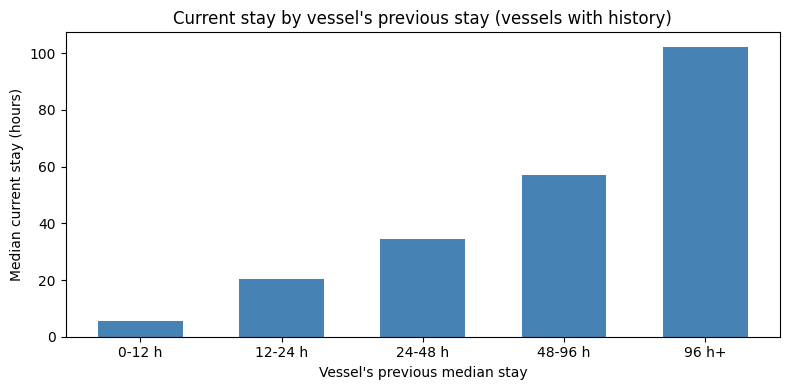

In [31]:
display(
    dev.groupby("has_vessel_history")[target]
    .agg(port_calls="count", median_stay="median", mean_stay="mean")
    .round(1)
)

# Group vessels with history by their previous median stay
with_history = dev[dev["has_vessel_history"]]
previous_stay_bins = pd.cut(
    with_history["vessel_total_known_median"],
    bins=[0, 12, 24, 48, 96, np.inf],
    labels=["0-12 h", "12-24 h", "24-48 h", "48-96 h", "96 h+"],
)
history_stats = with_history.groupby(previous_stay_bins, observed=True)[target].agg(
    port_calls="count", median_stay="median"
)
display(history_stats.round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(history_stats.index.astype(str), history_stats["median_stay"], color="steelblue", width=0.6)
ax.set_xlabel("Vessel's previous median stay")
ax.set_ylabel("Median current stay (hours)")
ax.set_title("Current stay by vessel's previous stay (vessels with history)")
plt.tight_layout()
plt.show()

**My observations:**

- Calls with no known vessel history have a longer median stay (44 h) than calls with history (28 h).
  Calls with history come from vessels that visit repeatedly, so this gap may reflect the kind of vessel rather
  than the history itself.
- For vessels with history, the current stay rises steadily with the previous median stay: from about 5 h
  (previous 0 - 12 h) to about 102 h (previous 96 h+).

### 3.11 Port Stay and Congestion

The total stay includes time spent waiting for a berth, so a busier port may mean longer stays.
`state_waiting_vessels_d_minus_1` is the number of vessels waiting at the port on the previous day.
Most calls have no waiting vessels (median 0, 90th percentile 6, maximum 66), so calls are grouped
into bins of waiting vessels. The 25th and 75th percentiles show whether the whole spread of stays
moves, not only the median.

In [32]:
waiting_bins = pd.cut(
    dev["state_waiting_vessels_d_minus_1"],
    bins=[-1, 0, 1, 2, 5, 10, 20, np.inf],
    labels=["0", "1", "2", "3-5", "6-10", "11-20", "21+"],
)
congestion = dev.groupby(waiting_bins, observed=True)[target].agg(
    port_calls="count",
    q25=lambda x: x.quantile(0.25),
    median_stay="median",
    q75=lambda x: x.quantile(0.75),
)
congestion["ports"] = dev.groupby(waiting_bins, observed=True)["port"].nunique()
display(congestion.round(1))

,port_calls,q25,median_stay,q75,ports
state_waiting_vessels_d_minus_1,,,,,
0,74412,17.3,36.7,75.1,108
1,9504,18.2,36.6,80.1,26
2,4422,18.2,37.2,86.5,21
3-5,8280,18.9,36.3,80.1,17
6-10,4240,20.7,38.3,86.4,8
11-20,2258,26.1,50.1,112.0,3
21+,5507,31.8,67.2,184.3,1


In [33]:
# The high-congestion bins come almost only from Santos (BRSSZ), so check the effect within that port
santos = dev[dev["port"] == "BRSSZ"]
santos_bins = pd.cut(
    santos["state_waiting_vessels_d_minus_1"],
    bins=[-1, 0, 5, 10, 20, np.inf],
    labels=["0", "1-5", "6-10", "11-20", "21+"],
)
display(santos.groupby(santos_bins, observed=True)[target].agg(port_calls="count", median_stay="median").round(1))

,port_calls,median_stay
state_waiting_vessels_d_minus_1,,
0,766,41.6
1-5,3105,42.2
6-10,1427,42.0
11-20,2228,50.1
21+,5507,67.2


**My observations:**

- Up to 10 waiting vessels, the stay barely changes: median about 37 h, middle 50% about 17 - 87 h in every bin.
- Above 10, the whole distribution shifts up: for 21+ waiting vessels the median is 67 h and the middle 50% is
  about 32 - 184 h.
- The spread within every bin is wide.
- 11 - 20 waiting vessels occur at only 3 ports, and 21+ only at Santos (BRSSZ). Within Santos the median still
  rises: about 42 h (up to 10 waiting), 50 h (11 - 20) and 67 h (21+).

### 3.12 Correlation Screening

Each eligible feature's Spearman (rank) correlation with the stay is calculated on the development data.
Eligible features are those the dictionary marks as available at arrival, plus the columns created in this
EDA. Rank correlation is used because it is not distorted by the very long stays.

Eligible features: 124 | numeric features screened: 118


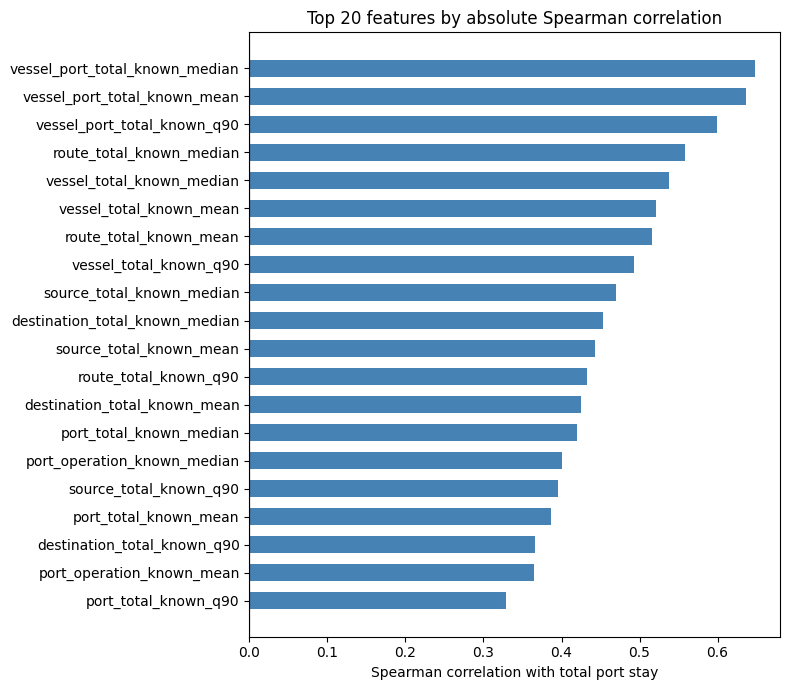

Weather feature correlations:


,spearman
wind_speed_10m_max_prev_7d,-0.124
wind_speed_10m_max_prev_3d,-0.113
wind_gusts_10m_max_prev_7d,-0.105
wind_speed_10m_max_prev_1d,-0.100
wind_gusts_10m_max_prev_3d,-0.096
wind_gusts_10m_max_prev_1d,-0.084
temperature_2m_mean_prev_7d,-0.006
temperature_2m_mean_prev_3d,-0.004
temperature_2m_mean_prev_1d,-0.000
rain_sum_prev_1d,0.017


Columns created in this EDA:


,spearman
has_vessel_history,-0.192
n_operations,-0.248
arrival_month,0.039
holidays_next_7d,0.002


In [34]:
# Only columns the dictionary marks as features available at arrival, plus the new EDA columns
eligible_features = dictionary_in_data.loc[
    (dictionary_in_data["modeling_role"] == "feature")
    & dictionary_in_data["availability_at_prediction_time"].isin(["yes", "historical_only"]),
    "column",
].tolist() + ["n_operations", "has_vessel_history", "arrival_month", "holidays_next_7d"]

numeric_features = [
    col for col in eligible_features
    if pd.api.types.is_numeric_dtype(dev[col]) and col not in constant_columns
]
print("Eligible features:", len(eligible_features), "| numeric features screened:", len(numeric_features))
correlations = (
    dev[numeric_features].astype(float)
    .corrwith(dev[target], method="spearman")
    .dropna()
)
top_correlations = correlations.reindex(correlations.abs().sort_values(ascending=False).index).head(20)[::-1]

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top_correlations.index, top_correlations.values, color="steelblue", height=0.6)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Spearman correlation with total port stay")
ax.set_title("Top 20 features by absolute Spearman correlation")
plt.tight_layout()
plt.show()

weather_columns = groups[groups == "Weather (before arrival)"].index
print("Weather feature correlations:")
display(correlations.reindex(weather_columns).sort_values().round(3).to_frame("spearman"))

print("Columns created in this EDA:")
display(correlations.reindex(["has_vessel_history", "n_operations", "arrival_month", "holidays_next_7d"]).round(3).to_frame("spearman"))

**My observations:**

- The strongest correlations are with history features: vessel at the same port (about 0.65), route (about 0.56),
  vessel overall (about 0.54) and port (about 0.42).
- History correlations are calculated only on calls that have that history (e.g. about 31% of calls for vessel at
  the same port), so they are not directly comparable with fully populated features.
- Weather is only weakly related: wind about -0.08 to -0.12, rain and temperature close to 0.
- Of the columns created in this EDA, `n_operations` (-0.25) and `has_vessel_history` (-0.19) are moderately
  related to the stay; `arrival_month` (0.04) and
  `holidays_next_7d` (0.002) are close to 0.

### 3.13 EDA Summary and Next Steps

**Data quality**

- The target has no missing, zero or negative values, but is strongly right-skewed (skewness 3.5).
- Missing values are concentrated in the history features and occur exactly when no earlier
  history exists.
- `op_tipo_operacao_nao_mapeado` is constant.
- 1,394 records (1.1%) share port, arrival time and stay with another record (164 of them identical
  except the ID); 278 calls declare 9 - 16 operations; 598 stays are under 1 hour.
- 0.4% of calls have no state or region.
- Leakage: all features are documented in the data dictionary as available at arrival.

**Main patterns in port stay** (development data)

- Port and declared operation type are strongly related to the stay.
- Past behaviour (vessel, route and port history) is the most informative group of features.
- Congestion matters only at high levels (more than 10 waiting vessels). High congestion occurs almost
  only at Santos (BRSSZ), but the effect is still visible within Santos alone.
- Weather and calendar effects are weak, and public holidays (external source: the `holidays`
  library) show no visible effect.

**My data preparation plan**

- I will drop the constant column `op_tipo_operacao_nao_mapeado`.
- I will leave missing history values as NaN, since they mean "no earlier visit", and add a
  `has_vessel_history` flag. LightGBM handles NaN directly, so no filling is needed.
- The records sharing a visit and the stays under 1 hour cannot be confirmed as errors. I will train once
  with and once without them, removing them from the training data only so the validation data stays the
  same, and keep whichever gives the lower validation error.
- I will keep the very long stays and the calls with unusual operation counts. The influence of long stays is
  tested through the log-target experiment and shown by reporting RMSE alongside MAE.

**Modelling plan**

- **Data use:** model-development decisions (features, transformations, model choice) use only
  train (Jan 2023 - Jun 2024) and validation (Jul 2024 - Jun 2025, including the calibration split).
  `final_test` is used once, after all decisions are made.
- **Metrics:** MAE in hours (main) and RMSE (secondary).
- **Baseline:** median stay per port, calculated on the training data only, with the overall
  training median as a fallback for ports not seen in training.
- **Model:** a gradient-boosted tree model (e.g. LightGBM), which handles missing values and
  non-linear effects.
- **Experiments**, each compared on the validation period:
  - original target vs `log(1 + stay)`;
  - with and without the new features `has_vessel_history` and `n_operations`;
  - with and without `holidays_next_7d` (Brazilian national and state holidays, Section 3.9);
  - with and without the weather features.

  None of these is assumed to help; each is kept only if it improves the validation results.

**Limitations to keep in mind**

- The declared operations (`op_*`) are assumed to be registered before arrival. If they were recorded
  afterwards, they would leak some information about the visit. The same applies to the route features,
  which use the reported next port.
- The effect of very high congestion is learned almost entirely from Santos, so the model's error at
  Santos is checked separately from the other ports.

**Out of scope**

- Vessel characteristics (type, size, cargo volume): there is no vessel identifier to join external
  vessel data, and such data usually requires a paid source.

## 4. Feature Preparation

### 4.1 Feature Sets

I start from the columns the data dictionary marks as features available at arrival, drop the constant
column, and add the features created during the EDA. The features are kept in named groups so that each
experiment in the modelling plan can switch a group on or off.

In [35]:
dictionary_features = dictionary_in_data.loc[
    (dictionary_in_data["modeling_role"] == "feature")
    & dictionary_in_data["availability_at_prediction_time"].isin(["yes", "historical_only"]),
    "column",
].tolist()

base_features = [col for col in dictionary_features if col not in constant_columns]
weather_features = [col for col in base_features if groups[col] == "Weather (before arrival)"]
eda_features = ["has_vessel_history", "n_operations"]
holiday_features = ["holidays_next_7d"]

all_features = base_features + eda_features + holiday_features
categorical_features = [col for col in all_features if df[col].dtype == "object"]

display(pd.Series({
    "Dataset features (dictionary, constant column dropped)": len(base_features),
    "   of which weather": len(weather_features),
    "Created in the EDA": len(eda_features),
    "Holidays (external)": len(holiday_features),
    "All features": len(all_features),
}).to_frame("Number of features"))
print("Categorical features:", categorical_features)

,Number of features
"Dataset features (dictionary, constant column dropped)",119
of which weather,15
Created in the EDA,2
Holidays (external),1
All features,122


Categorical features: ['port', 'arrival_shift', 'arrival_season', 'state', 'region']


The dictionary labels are checked against my own reasoning. Most feature names state the time window
they use, so the features are split into those that look only at the past and those that describe the
arrival itself:

In [36]:
import re

past_only = [col for col in dictionary_features if re.search(r"prev_\d+d|d_minus_1|_known_", col)]
describes_arrival = [col for col in dictionary_features if col not in past_only]

print(f"Past-only by name (prev_Xd, d_minus_1, _known_): {len(past_only)}")
print(f"Describe the arrival itself: {len(describes_arrival)}")
display(pd.Series(describes_arrival).map(groups).value_counts().to_frame("Columns"))

Past-only by name (prev_Xd, d_minus_1, _known_): 89
Describe the arrival itself: 31


,Columns
Declared operation type,17
Arrival calendar,11
Location,3


**Why these are known at arrival:**

| Features | Reason |
|---|---|
| Past-only (89) | The names show they use only a window before arrival (`prev_1d/3d/7d`, `d_minus_1`) or earlier visits that had already finished (`_known_`). This matches Section 3.3: history is missing exactly when there is no earlier visit. |
| Location (3) | The port of arrival is known. |
| Arrival calendar (11) | Calculated from the arrival timestamp itself. |
| Declared operations (17) | The operation type declared for the call. In Porto Sem Papel the shipping agent registers the planned operations before arrival. This cannot be verified from the file, so it is an assumption. |

Helper columns created during the EDA that are **not** used as features: `arrival_ts`, `model_split`,
`arrival_month` and `arrival_weekday` (the dataset already has the same information as `arrival_month_sin/cos`
and `arrival_dow_sin/cos`), and `stay_vs_port_median`, which is calculated from the target and would leak it.
This is checked below.

In [37]:
excluded = ["port_call_id", "arrival_port_ts", "split", target, "arrival_ts", "model_split",
            "arrival_month", "arrival_weekday", "stay_vs_port_median"]
assert not set(excluded) & set(all_features), "an excluded column is in the feature list"
assert all(col in df.columns for col in all_features), "a feature is missing from the data"
print("No excluded columns in the feature list.")

No excluded columns in the feature list.


### 4.2 Train, Validation and Test Data

The text columns are converted to the pandas `category` type, which gradient-boosted tree libraries can use
directly, and the True/False columns to 0/1. Missing values are left as NaN. The categories are defined from
the training data only, so a port that first appears later (e.g. the 7 ports unseen in training) is treated
as unknown.

In [38]:
features = df[all_features].copy()

bool_columns = features.select_dtypes("bool").columns
features[bool_columns] = features[bool_columns].astype(int)

is_train = df["model_split"] == "train"
for col in categorical_features:
    train_categories = sorted(features.loc[is_train, col].dropna().unique())
    features[col] = pd.Categorical(features[col], categories=train_categories)

X_train, y_train = features[is_train], df.loc[is_train, target]
X_val, y_val = features[df["model_split"] == "validation"], df.loc[df["model_split"] == "validation", target]
X_test, y_test = features[df["model_split"] == "final_test"], df.loc[df["model_split"] == "final_test", target]

display(pd.DataFrame({
    "rows": [len(X_train), len(X_val), len(X_test)],
    "first_arrival": [df.loc[X.index, "arrival_ts"].min().date() for X in (X_train, X_val, X_test)],
    "last_arrival": [df.loc[X.index, "arrival_ts"].max().date() for X in (X_train, X_val, X_test)],
    "unknown_port": [X["port"].isna().sum() for X in (X_train, X_val, X_test)],
}, index=["train", "validation", "final_test"]))
print("Feature columns:", X_train.shape[1])

,rows,first_arrival,last_arrival,unknown_port
train,66909,2023-01-01,2024-06-30,0
validation,41714,2024-07-01,2025-06-30,98
final_test,21002,2025-07-01,2025-12-31,49


Feature columns: 122


## 5. Modelling

### 5.1 Evaluation Metrics

Every model is scored on the validation period with MAE in hours (main metric) and RMSE (secondary metric,
which weights large errors more heavily).

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error


def evaluate(y_true, y_pred):
    """MAE and RMSE in hours."""
    return {
        "MAE (h)": mean_absolute_error(y_true, y_pred),
        "RMSE (h)": np.sqrt(mean_squared_error(y_true, y_pred)),
    }


results = {}

### 5.2 Baseline: Median Stay per Port

The baseline predicts the median training stay of the call's port. Ports not seen in training get the overall
training median.

In [40]:
train_port_median = y_train.groupby(df.loc[is_train, "port"]).median()
train_median = y_train.median()


def predict_port_median(index):
    return df.loc[index, "port"].map(train_port_median).fillna(train_median)


results["Baseline: median per port"] = evaluate(y_val, predict_port_median(X_val.index))
display(pd.DataFrame(results).T.round(1))

,MAE (h),RMSE (h)
Baseline: median per port,49.1,101.7


### 5.3 First LightGBM Model

A LightGBM model with all 122 features, trained on the original target (hours). The settings are common
starting values. The number of trees is chosen by early stopping: training stops when the validation MAE has
not improved for 100 rounds. Because the same validation period is then used to score the model, its result is
slightly optimistic; the final test set gives the unbiased result.

In [41]:
import lightgbm as lgb


def make_lgbm(objective="regression", seed=42, n_estimators=3000, learning_rate=0.05, num_leaves=63):
    """LightGBM with the settings used throughout this notebook."""
    return lgb.LGBMRegressor(
        objective=objective,
        metric="l1",
        n_estimators=n_estimators,
        learning_rate=learning_rate,
        num_leaves=num_leaves,
        min_child_samples=50,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        random_state=seed,
        verbose=-1,
    )


def train_lgbm(X_tr, y_tr, X_va, y_va, objective="regression", seed=42, **settings):
    """Train with early stopping: stop when validation MAE has not improved for 100 trees."""
    model = make_lgbm(objective, seed, **settings)
    model.fit(X_tr, y_tr, eval_X=(X_va,), eval_y=(y_va,), callbacks=[lgb.early_stopping(100, verbose=False)])
    return model


model_all = train_lgbm(X_train, y_train, X_val, y_val)
print("Trees used:", model_all.best_iteration_)

results["LightGBM: hours, squared-error loss"] = evaluate(y_val, model_all.predict(X_val))
display(pd.DataFrame(results).T.round(1))

Trees used: 90


,MAE (h),RMSE (h)
Baseline: median per port,49.1,101.7
"LightGBM: hours, squared-error loss",46.5,85.0


### 5.4 Target and Loss Experiment

The first model is trained on hours with squared-error loss (LightGBM's default), so it predicts close to the
average stay, which the long stays pull upwards. Two separate choices can change this:

- **Target scale:** hours, or `log(1 + stay)`. Predictions from the log model are converted back to hours with
  `np.expm1` before scoring.
- **Loss:** squared error, or absolute error (MAE loss, `objective="l1"`), the same quantity as the main metric.

All four combinations are compared with the same features and settings.

In [42]:
model_log = train_lgbm(X_train, np.log1p(y_train), X_val, np.log1p(y_val))
results["LightGBM: log target, squared-error loss"] = evaluate(y_val, np.expm1(model_log.predict(X_val)))

model_l1 = train_lgbm(X_train, y_train, X_val, y_val, objective="l1")
results["LightGBM: hours, MAE loss"] = evaluate(y_val, model_l1.predict(X_val))

model_log_l1 = train_lgbm(X_train, np.log1p(y_train), X_val, np.log1p(y_val), objective="l1")
results["LightGBM: log target, MAE loss"] = evaluate(y_val, np.expm1(model_log_l1.predict(X_val)))

display(pd.DataFrame(results).T.round(1))

,MAE (h),RMSE (h)
Baseline: median per port,49.1,101.7
"LightGBM: hours, squared-error loss",46.5,85.0
"LightGBM: log target, squared-error loss",41.7,90.0
"LightGBM: hours, MAE loss",41.6,90.4
"LightGBM: log target, MAE loss",41.6,91.1


**My observations:**

- The default model (hours, squared-error loss) beats the baseline by 2.6 h MAE.
- Changing either the target scale or the loss lowers the MAE to about 41.6 - 41.7 h, 15% below the baseline.
  Combining both gives no further gain (41.6 h).
- The default model has the lowest RMSE (85.0 h): it handles the very long stays better, at the cost of larger
  errors on typical stays.
- Hours with MAE loss is used from here on, as it has the lowest MAE and needs no conversion back to hours.

### 5.5 Feature Group Experiments

From here on the model is LightGBM trained on hours with MAE loss. Each feature group is removed in turn, and the
validation result is compared with the model that uses all features. If removing a group makes the MAE worse,
the group helps.

In [43]:
def run_experiment(feature_list, train_index=None):
    """Train LightGBM (hours, MAE loss) on the given features and score it on validation."""
    train_index = X_train.index if train_index is None else train_index
    model = train_lgbm(X_train.loc[train_index, feature_list], y_train.loc[train_index],
                       X_val[feature_list], y_val, objective="l1")
    return {"features": len(feature_list), **evaluate(y_val, model.predict(X_val[feature_list]))}


base_features_no_weather = [col for col in base_features if col not in weather_features]

feature_experiments = {
    "All features": all_features,
    "Without weather": [col for col in all_features if col not in weather_features],
    "Without holidays": [col for col in all_features if col not in holiday_features],
    "Without EDA features (has_vessel_history, n_operations)":
        [col for col in all_features if col not in eda_features],
    "Without all three groups": base_features_no_weather,
}

feature_results = pd.DataFrame({name: run_experiment(cols) for name, cols in feature_experiments.items()}).T
feature_results["MAE change vs all (h)"] = feature_results["MAE (h)"] - feature_results.loc["All features", "MAE (h)"]
display(feature_results.round(2))

,features,MAE (h),RMSE (h),MAE change vs all (h)
All features,122.0,41.59,90.36,0.00
Without weather,107.0,41.56,90.01,-0.03
Without holidays,121.0,41.60,90.16,0.01
"Without EDA features (has_vessel_history, n_operations)",120.0,41.65,90.16,0.07
Without all three groups,104.0,41.61,90.02,0.03


To judge whether these differences are meaningful, the all-features model is retrained with three different
random seeds. The seed changes which rows and columns each tree samples, so the spread shows how much the MAE
varies by chance alone.

In [44]:
seed_mae = {}
for seed in [1, 2, 3]:
    model = train_lgbm(X_train, y_train, X_val, y_val, objective="l1", seed=seed)
    seed_mae[f"seed {seed}"] = mean_absolute_error(y_val, model.predict(X_val))

seed_mae = pd.Series(seed_mae)
display(seed_mae.round(2).to_frame("MAE (h)"))
print(f"Range across seeds: {seed_mae.max() - seed_mae.min():.2f} h")

,MAE (h)
seed 1,41.53
seed 2,41.60
seed 3,41.60


Range across seeds: 0.07 h


**My observations:**

- Removing weather, holidays or the EDA features changes the validation MAE by at most 0.07 h (about 4 minutes).
  Removing all three groups together changes it by 0.03 h.
- Retraining the same model with different random seeds changes the MAE by up to 0.07 h as well.
- So none of the three groups measurably helps or hurts the model. This matches the EDA, where weather and
  holidays were only weakly related to the stay, and the information in `has_vessel_history` and `n_operations`
  is already contained in other features (the history counts and the `op_*` flags).

### 5.6 Training vs Validation Loss

Carried forward from 5.4 and 5.5: hours with MAE loss, and the 104 dataset features without weather, holidays
and the EDA features. To see whether the model overfits, it is trained for a fixed 1,000 trees while the MAE
on both the training and the validation data is recorded after every tree.

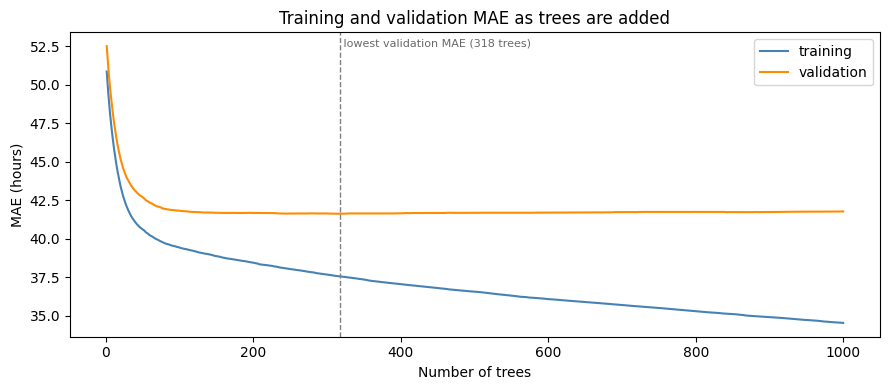

,training MAE (h),validation MAE (h)
318 trees (lowest validation MAE),37.54,41.61
"1,000 trees",34.53,41.76


In [45]:
selected_features = base_features_no_weather

learning_curve = {}
model_curve = make_lgbm(objective="l1", n_estimators=1000)
model_curve.fit(
    X_train[selected_features], y_train,
    eval_X=(X_train[selected_features], X_val[selected_features]), eval_y=(y_train, y_val),
    eval_names=["training", "validation"],
    callbacks=[lgb.record_evaluation(learning_curve)],
)
train_curve = np.array(learning_curve["training"]["l1"])
val_curve = np.array(learning_curve["validation"]["l1"])
best_trees = int(val_curve.argmin()) + 1

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(train_curve) + 1), train_curve, label="training", color="steelblue")
ax.plot(range(1, len(val_curve) + 1), val_curve, label="validation", color="darkorange")
ax.axvline(best_trees, color="grey", linestyle="--", linewidth=1)
ax.text(best_trees, val_curve.max(), f" lowest validation MAE ({best_trees} trees)", color="dimgrey", fontsize=8)
ax.set_xlabel("Number of trees")
ax.set_ylabel("MAE (hours)")
ax.set_title("Training and validation MAE as trees are added")
ax.legend()
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "training MAE (h)": [train_curve[best_trees - 1], train_curve[-1]],
    "validation MAE (h)": [val_curve[best_trees - 1], val_curve[-1]],
}, index=[f"{best_trees} trees (lowest validation MAE)", "1,000 trees"]).round(2))

**My observations:**

- Validation MAE is lowest at 318 trees (41.6 h). The training MAE at that point is 37.5 h, so the model is about
  4 h more accurate on the data it was trained on than on the later, unseen period.
- After 318 trees the training MAE keeps falling (34.5 h at 1,000 trees) while the validation MAE rises slightly
  (41.8 h): extra trees only fit the training data more closely. Early stopping ends training near the lowest
  validation MAE, so this is avoided.

### 5.7 Training-Data Cleanup

Section 3.5 found records that share port, arrival time and stay with another record (164 of them identical in
every column except `port_call_id`), and stays under 1 hour (the shortest is about 1 minute). These records have different
`port_call_id` values and may represent distinct operations of one visit, so neither can be confirmed as an
error. The model is therefore trained with and without them. Two versions of the removal are tested: removing
only the records identical except the ID, and removing every extra record with matching port, arrival and stay
(which also removes e.g. the loading record of a loading/unloading pair). In both, the first record of each group is kept.
Records are removed from the training data only, so the validation data and the comparison stay the same.

In [46]:
# Extra matching records, keeping the first record of each group
identical_copy = df.duplicated(subset=[col for col in df.columns if col != "port_call_id"], keep="first")
extra_copy = df.duplicated(subset=same_visit_key, keep="first")
under_1h = df[target] < 1

cleanup_options = {
    "All training records": X_train.index,
    "Without records identical except the ID": X_train.index[~identical_copy[X_train.index]],
    "Without extra records with matching port, arrival and stay": X_train.index[~extra_copy[X_train.index]],
    "Without stays under 1 hour": X_train.index[~under_1h[X_train.index]],
    "Without both": X_train.index[~(extra_copy | under_1h)[X_train.index]],
}

cleanup_results = pd.DataFrame({
    name: {"training records": len(index), **run_experiment(selected_features, index)}
    for name, index in cleanup_options.items()
}).T.drop(columns="features").astype({"training records": int})
cleanup_results["MAE change (h)"] = cleanup_results["MAE (h)"] - cleanup_results.loc["All training records", "MAE (h)"]
display(cleanup_results.round(2))

,training records,MAE (h),RMSE (h),MAE change (h)
All training records,66909,41.61,90.02,0.00
Without records identical except the ID,66844,41.70,90.12,0.09
"Without extra records with matching port, arrival and stay",66525,41.70,90.24,0.09
Without stays under 1 hour,66615,41.61,90.28,0.00
Without both,66231,41.66,90.42,0.05


**My observations:**

- Removing the records identical except the ID, every extra record with matching port, arrival and stay, or the
  stays under 1 hour changes the validation MAE by at most 0.09 h, close to the 0.07 h variation between
  random seeds.
- None of the cleanup options improves the model. Since these records have different `port_call_id` values and
  may represent distinct operations, all training records are kept.

### 5.8 Model Settings

So far the model has used common starting values: trees with up to 63 leaves and a learning rate of 0.05.
A small grid of 3 x 3 values is tried:

- **`num_leaves`** (31, 63, 127): the maximum size of each tree. Larger trees can learn more detailed patterns
  but overfit more easily.
- **`learning_rate`** (0.03, 0.05, 0.1): how much each new tree corrects the previous ones. A smaller rate needs
  more trees but often generalises slightly better.

The number of trees is still chosen by early stopping.

In [47]:
settings_results = []
for num_leaves in [31, 63, 127]:
    for learning_rate in [0.03, 0.05, 0.1]:
        model = train_lgbm(X_train[selected_features], y_train, X_val[selected_features], y_val,
                           objective="l1", num_leaves=num_leaves, learning_rate=learning_rate)
        settings_results.append({
            "num_leaves": num_leaves,
            "learning_rate": learning_rate,
            "trees": model.best_iteration_,
            **evaluate(y_val, model.predict(X_val[selected_features])),
        })

settings_results = pd.DataFrame(settings_results)
print("Validation MAE (h):")
display(settings_results.pivot(index="num_leaves", columns="learning_rate", values="MAE (h)").round(2))
print("Number of trees chosen by early stopping:")
display(settings_results.pivot(index="num_leaves", columns="learning_rate", values="trees"))

Validation MAE (h):


learning_rate,0.03,0.05,0.10
num_leaves,,,
31,41.66,41.68,41.85
63,41.64,41.61,41.71
127,41.62,41.62,41.78


Number of trees chosen by early stopping:


learning_rate,0.03,0.05,0.10
num_leaves,,,
31,989,641,121
63,469,318,81
127,312,168,109


**My observations:**

- The validation MAE ranges from 41.61 to 41.85 h across the 9 combinations.
- With a learning rate of 0.03 or 0.05 the MAE is 41.61 - 41.68 h for every tree size, within the 0.07 h
  variation between random seeds. A learning rate of 0.1 is slightly worse (41.71 - 41.85 h).
- Smaller learning rates and smaller trees need more trees (up to 989), but end at about the same MAE.
- The starting values (63 leaves, learning rate 0.05) give the lowest MAE, so they are kept.

## 6. Final Evaluation on the Test Set

### 6.1 Final Model

The final model uses the choices made on the validation period: LightGBM trained on hours with MAE loss, the
104 dataset features (without weather, holidays and the EDA features), all training records, 63 leaves and a
learning rate of 0.05.

It is retrained on train + validation (Jan 2023 - Jun 2025), so it learns from the most recent data before the
test period. There is no separate validation period left for early stopping, so the number of trees is set to
20% more than early stopping chose in Section 5.6, as the training data is larger. The categories (e.g. ports)
are redefined from train + validation, and the baseline is rebuilt from the same data.

The test period (Jul - Dec 2025) is used here for the first and only time.

In [48]:
is_dev = df["model_split"] != "final_test"

# Same preparation as Section 4.2, with categories taken from train + validation
final_features = df[selected_features].copy()
final_bool = final_features.select_dtypes("bool").columns
final_features[final_bool] = final_features[final_bool].astype(int)
for col in [c for c in categorical_features if c in selected_features]:
    dev_categories = sorted(final_features.loc[is_dev, col].dropna().unique())
    final_features[col] = pd.Categorical(final_features[col], categories=dev_categories)

X_dev, y_dev = final_features[is_dev], df.loc[is_dev, target]
X_test_final, y_test_final = final_features[~is_dev], df.loc[~is_dev, target]

final_trees = int(round(best_trees * 1.2))
final_model = make_lgbm(objective="l1", n_estimators=final_trees)
final_model.fit(X_dev, y_dev)
test_prediction = final_model.predict(X_test_final)

# Baseline rebuilt from train + validation
dev_port_median = y_dev.groupby(df.loc[is_dev, "port"]).median()
baseline_test_prediction = df.loc[~is_dev, "port"].map(dev_port_median).fillna(y_dev.median()).values

print(f"Training records: {len(X_dev):,} | test records: {len(X_test_final):,} | trees: {final_trees}")

Training records: 108,623 | test records: 21,002 | trees: 382


### 6.2 Test Results

Besides MAE and RMSE, the median absolute error is shown: half of the calls are predicted closer than this.

In [49]:
from sklearn.metrics import median_absolute_error


def evaluate_test(y_true, y_pred):
    return {
        "MAE (h)": mean_absolute_error(y_true, y_pred),
        "RMSE (h)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "Median absolute error (h)": median_absolute_error(y_true, y_pred),
    }


test_results = pd.DataFrame({
    "Baseline: median per port": evaluate_test(y_test_final, baseline_test_prediction),
    "Final LightGBM model": evaluate_test(y_test_final, test_prediction),
}).T
display(test_results.round(1))

improvement = 1 - test_results.loc["Final LightGBM model", "MAE (h)"] / test_results.loc["Baseline: median per port", "MAE (h)"]
print(f"MAE improvement over the baseline: {improvement * 100:.1f}%")

,MAE (h),RMSE (h),Median absolute error (h)
Baseline: median per port,45.7,92.6,20.1
Final LightGBM model,38.0,80.0,15.0


MAE improvement over the baseline: 16.9%


**My observations:**

- On the test period the final model has an MAE of 38.0 h, against 45.7 h for the baseline (16.9% lower).
  RMSE falls from 92.6 to 80.0 h.
- The median absolute error is 15.0 h: half of the test calls are predicted within 15 hours of the actual stay.
- The test MAE is close to the validation MAE (41.6 h), so the choices made on validation carry over to the
  later period.

### 6.3 Error by Stay Length

The test calls are grouped by their actual stay, to see where the error comes from. "Share of total error" is
each group's part of the summed absolute error of the model.

In [50]:
test_calls = df.loc[~is_dev, [target, "port"]].copy()
test_calls["prediction"] = test_prediction
test_calls["baseline"] = baseline_test_prediction
test_calls["abs_error"] = (test_calls["prediction"] - test_calls[target]).abs()
test_calls["stay_group"] = pd.cut(
    test_calls[target], bins=[0, 24, 72, 168, np.inf],
    labels=["under 1 day", "1 - 3 days", "3 - 7 days", "over 7 days"],
)


def error_summary(calls):
    return pd.Series({
        "port_calls": len(calls),
        "model MAE (h)": mean_absolute_error(calls[target], calls["prediction"]),
        "baseline MAE (h)": mean_absolute_error(calls[target], calls["baseline"]),
        "model underpredicts (%)": (calls["prediction"] < calls[target]).mean() * 100,
        "share of total error (%)": calls["abs_error"].sum() / test_calls["abs_error"].sum() * 100,
    })


by_length = test_calls.groupby("stay_group", observed=True).apply(error_summary)
display(by_length.astype({"port_calls": int}).round(1))

,port_calls,model MAE (h),baseline MAE (h),model underpredicts (%),share of total error (%)
stay_group,,,,,
under 1 day,6430,14.2,18.9,18.8,11.4
1 - 3 days,8581,16.7,14.1,46.9,18.0
3 - 7 days,4066,41.7,58.2,79.6,21.3
over 7 days,1925,204.1,249.1,99.2,49.3


**My observations:**

- Stays over 7 days are 9% of the test calls but cause 49% of the model's total error. Their MAE is 204 h, and
  the model predicts too short for 99% of them. Part of this comes from the MAE loss: a model trained with it
  predicts the typical (median) stay for similar calls, so rare very long stays are predicted too short by
  design.
- For stays under 3 days (71% of calls) the MAE is 14 - 17 h.
- The model beats the baseline in every group except 1 - 3 days (16.7 vs 14.1 h), where the port median
  happens to be close to the actual stay.

### 6.4 Santos vs Other Ports

Very high congestion occurs only at Santos (BRSSZ), so the error there is compared with the other ports, for all
stays and for stays over 7 days.

In [51]:
test_calls["port_group"] = np.where(test_calls["port"] == "BRSSZ", "Santos (BRSSZ)", "Other ports")

santos_rows = {}
for group, calls in test_calls.groupby("port_group"):
    santos_rows[(group, "all stays")] = error_summary(calls)
    santos_rows[(group, "over 7 days")] = error_summary(calls[calls[target] > 168])

santos_table = pd.DataFrame(santos_rows).T.drop(columns="share of total error (%)")
santos_table["model improvement vs baseline (%)"] = (
    1 - santos_table["model MAE (h)"] / santos_table["baseline MAE (h)"]
) * 100
display(santos_table.astype({"port_calls": int}).round(1))

port_calls  model MAE (h)  baseline MAE (h)  model underpredicts (%)  \
Other ports    all stays         18262           34.8              40.9                     49.9   
               over 7 days        1403          205.3             237.5                     99.5   
Santos (BRSSZ) all stays          2740           58.9              77.6                     46.3   
               over 7 days         522          200.9             280.4                     98.5   

                            model improvement vs baseline (%)  
Other ports    all stays                                 14.8  
               over 7 days                               13.6  
Santos (BRSSZ) all stays                                 24.1  
               over 7 days                               28.4

**My observations:**

- At Santos the model improves on the baseline more than at other ports: 24% lower MAE for all stays (vs 15%),
  and 28% for stays over 7 days (vs 14%).
- In absolute terms, long stays remain poorly predicted at Santos as well: MAE about 200 h, and 98.5% predicted
  too short.
- Santos is where congestion and stays are highest. Whether its larger improvement comes from the congestion
  features or from other features (e.g. route history) was not tested separately.

### 6.5 Which Features Matter Most

LightGBM records how much each feature reduced the training error across all the splits that used it
("gain"). This is shown as a share of the total, for the 15 most important features and summed by the column
groups from Section 3.1. It shows what the model relies on, not that a feature causes longer stays. Gain is measured on the training
data and can favour features with many distinct values, such as `port` (108 ports), so the shares are a guide
rather than exact.

In [52]:
importance = pd.DataFrame({
    "feature": final_model.feature_name_,
    "gain": final_model.booster_.feature_importance(importance_type="gain"),
})
importance["share (%)"] = importance["gain"] / importance["gain"].sum() * 100
importance["group"] = importance["feature"].map(column_group)
importance = importance.sort_values("share (%)", ascending=False)

print("Top 15 features:")
display(importance.head(15)[["feature", "group", "share (%)"]].round(1).reset_index(drop=True))

print("Importance by feature group:")
by_group = importance.groupby("group").agg(n_features=("feature", "count"), share=("share (%)", "sum"))
display(by_group.sort_values("share", ascending=False).rename(columns={"share": "share (%)"}).round(1))

Top 15 features:


,feature,group,share (%)
0,route_total_known_median,Route history,34.3
1,port,Location,17.3
2,route_total_known_mean,Route history,3.8
3,vessel_port_total_known_median,Vessel history,3.5
4,source_total_known_median,Route history,2.9
5,vessel_port_total_known_mean,Vessel history,2.0
6,destination_total_known_median,Route history,1.9
7,route_total_known_q90,Route history,1.7
8,op_abastecimento_bunker,Declared operation type,1.5
9,op_carga,Declared operation type,1.5


Importance by feature group:


,n_features,share (%)
group,,
Route history,12,51.1
Location,3,18.0
Vessel history,12,9.6
Port history,18,6.9
Declared operation type,16,6.3
Port traffic & congestion (before arrival),22,3.4
Arrival calendar,11,3.3
Port operation mix (before arrival),10,1.5


**My observations:**

- Route history is the most important group (51% of the gain). The single strongest feature is
  `route_total_known_median`, the median stay of earlier calls with the same reported previous and next port
  (34%).
- The port itself is second (17%), which is the information the baseline uses.
- Vessel history (10%), port history (7%) and the declared operations (6%) add smaller parts.
- Congestion (3.4%) and the arrival calendar (3.3%) contribute little overall. Very high congestion occurs only
  at Santos, which is a small part of all calls (13% of test calls).
- So the model mostly predicts a stay from how long similar earlier calls took: same route, same port, same
  vessel.